# Examen ICCD753 — Recuperación de Información
## Corpus: NFCorpus | Modelos: TF-IDF y BM25
**Escuela Politécnica Nacional**  
Nombre: Dany Molina  
Fecha: 18/11/2026

---
## 0. Instalación de dependencias

In [1]:
%pip install datasets nltk scikit-learn rank_bm25 flask flask-ngrok pyngrok

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


---
## 1. Carga del corpus NFCorpus

In [2]:
from datasets import load_dataset

print("Cargando corpus NFCorpus...")
# Documentos (corpus)
corpus_ds = load_dataset("BeIR/nfcorpus", "corpus", split="corpus")
# Consultas
queries_ds = load_dataset("BeIR/nfcorpus", "queries", split="queries")
# Qrels (juicios de relevancia) — partición test
qrels_ds   = load_dataset("BeIR/nfcorpus-qrels", split="test")

print(f"Documentos en corpus : {len(corpus_ds):,}")
print(f"Consultas totales    : {len(queries_ds):,}")
print(f"Qrels (test)         : {len(qrels_ds):,}")

C:\Users\HP VICTUS\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Cargando corpus NFCorpus...


Documentos en corpus : 3,633
Consultas totales    : 3,237
Qrels (test)         : 12,334


In [3]:
# Vista rápida de las estructuras
print("=== Columnas corpus  ===", corpus_ds.column_names)
print("=== Columnas queries ===", queries_ds.column_names)
print("=== Columnas qrels   ===", qrels_ds.column_names)
print()
print("Ejemplo documento:", corpus_ds[0])
print("Ejemplo consulta :", queries_ds[0])
print("Ejemplo qrel     :", qrels_ds[0])

=== Columnas corpus  === ['_id', 'title', 'text']
=== Columnas queries === ['_id', 'title', 'text']
=== Columnas qrels   === ['query-id', 'corpus-id', 'score']

Ejemplo documento: {'_id': 'MED-10', 'title': 'Statin Use and Breast Cancer Survival: A Nationwide Cohort Study from Finland', 'text': 'Recent studies have suggested that statins, an established drug group in the prevention of cardiovascular mortality, could delay or prevent breast cancer recurrence but the effect on disease-specific mortality remains unclear. We evaluated risk of breast cancer death among statin users in a population-based cohort of breast cancer patients. The study cohort included all newly diagnosed breast cancer patients in Finland during 1995–2003 (31,236 cases), identified from the Finnish Cancer Registry. Information on statin use before and after the diagnosis was obtained from a national prescription database. We used the Cox proportional hazards regression method to estimate mortality among statin use

In [4]:
# Convertir a diccionarios Python para acceso rápido
# Documentos: {doc_id -> {title, text}}
docs = {}
for row in corpus_ds:
    doc_id = row["_id"]
    docs[doc_id] = {
        "title": row.get("title", ""),
        "text" : row.get("text",  "")
    }

# Consultas: {query_id -> text}
queries = {row["_id"]: row["text"] for row in queries_ds}

# Qrels test: {query_id -> {doc_id -> relevance_score}}
qrels = {}
for row in qrels_ds:
    qid  = row["query-id"]
    did  = row["corpus-id"]
    score = int(row["score"])
    if qid not in qrels:
        qrels[qid] = {}
    qrels[qid][did] = score

print(f"Documentos indexables : {len(docs):,}")
print(f"Consultas disponibles : {len(queries):,}")
print(f"Consultas con qrels   : {len(qrels):,}")

Documentos indexables : 3,633
Consultas disponibles : 3,237
Consultas con qrels   : 323


---
## 2. Preprocesamiento

**Decisiones de preprocesamiento:**

| Paso | Decisión | Justificación |
|------|----------|---------------|
| Tokenización | `nltk.word_tokenize` | Separa correctamente puntuación y contracciones |
| Normalización | Minúsculas + eliminación de no-alfanuméricos | Reduce variantes de la misma palabra |
| Stopwords | `nltk.stopwords` inglés | NFCorpus está en inglés; eliminar palabras vacías reduce ruido |
| Stemming | `PorterStemmer` | Agrupa variantes morfológicas (ej. *running* → *run*) sin necesidad de un lexicón completo |



In [5]:
import nltk, re
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

nltk.download("punkt",        quiet=True)
nltk.download("punkt_tab",    quiet=True)
nltk.download("stopwords",    quiet=True)

STOP_WORDS = set(stopwords.words("english"))
stemmer    = PorterStemmer()

def preprocess(text: str) -> list[str]:
    """Tokeniza, normaliza, elimina stopwords y aplica stemming."""
    text   = text.lower()
    tokens = word_tokenize(text)
    tokens = [re.sub(r"[^a-z0-9]", "", t) for t in tokens]  # solo alfanumérico
    tokens = [t for t in tokens if t and t not in STOP_WORDS]
    tokens = [stemmer.stem(t) for t in tokens]
    return tokens

# Prueba rápida
ejemplo = "Dietary fat intake and risk of cardiovascular diseases."
print("Original :", ejemplo)
print("Procesado:", preprocess(ejemplo))

Original : Dietary fat intake and risk of cardiovascular diseases.
Procesado: ['dietari', 'fat', 'intak', 'risk', 'cardiovascular', 'diseas']


---
## 3. Construcción del índice invertido y vocabulario

In [6]:
from collections import defaultdict
import math

# Tokenizar todos los documentos 
print("Preprocesando documentos...")
doc_ids    = list(docs.keys())          # orden estable
tokenized  = []                         # lista de listas de tokens
for i, did in enumerate(doc_ids):
    combined = docs[did]["title"] + " " + docs[did]["text"]
    tokenized.append(preprocess(combined))
    if (i + 1) % 5000 == 0:
        print(f"  {i+1:,} documentos procesados...")
print(f"{len(doc_ids):,} documentos tokenizados")

#Vocabulario
vocab = sorted({term for tokens in tokenized for term in tokens})
term2idx = {term: i for i, term in enumerate(vocab)}
print(f"Tamaño del vocabulario: {len(vocab):,} términos")

#Índice invertido
inverted_index = defaultdict(list)      # term -> [(doc_idx, tf), ...]
doc_tf = []                             # doc_tf[doc_idx] = {term: tf}

for doc_idx, tokens in enumerate(tokenized):
    tf_dict = defaultdict(int)
    for t in tokens:
        tf_dict[t] += 1
    doc_tf.append(dict(tf_dict))
    for term in tf_dict:
        inverted_index[term].append((doc_idx, tf_dict[term]))

print(f"Índice invertido: {len(inverted_index):,} entradas")
print("Ejemplo — término 'diet':", inverted_index.get("diet", [])[:5])

Preprocesando documentos...
3,633 documentos tokenizados
Tamaño del vocabulario: 27,869 términos
Índice invertido: 27,869 entradas
Ejemplo — término 'diet': [(7, 1), (11, 1), (16, 1), (20, 6), (24, 1)]


---
## 4. Modelo TF-IDF con similitud coseno

In [7]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer

# Usamos TfidfVectorizer de scikit-learn sobre los textos preprocesados
# (ya tokenizados y con stemming), usando un analyzer que devuelve
# los tokens tal como están (sin re-procesar).

print("Construyendo matriz TF-IDF...")

# Reconstruimos los documentos como texto de tokens ya procesados
processed_texts = [" ".join(tokens) for tokens in tokenized]

tfidf_vectorizer = TfidfVectorizer(
    analyzer="word",
    token_pattern=r"\S+",   # cada token es una secuencia sin espacios
    norm="l2"
)
tfidf_matrix = tfidf_vectorizer.fit_transform(processed_texts)  

print(f"Matriz TF-IDF: {tfidf_matrix.shape} (documentos × términos)")
print(f"Densidad     : {tfidf_matrix.nnz / (tfidf_matrix.shape[0]*tfidf_matrix.shape[1]):.4%}")

Construyendo matriz TF-IDF...
Matriz TF-IDF: (3633, 27869) (documentos × términos)
Densidad     : 0.3457%


In [8]:
from sklearn.metrics.pairwise import cosine_similarity

def search_tfidf(query: str, top_k: int = 10) -> list[dict]:
    """Recupera top_k documentos usando TF-IDF + coseno."""
    q_tokens  = preprocess(query)
    q_text    = " ".join(q_tokens)
    q_vec     = tfidf_vectorizer.transform([q_text])      # (1, vocab)
    scores    = cosine_similarity(q_vec, tfidf_matrix).flatten()  # (N_docs,)
    top_idx   = scores.argsort()[::-1][:top_k]

    results = []
    for rank, idx in enumerate(top_idx, start=1):
        did = doc_ids[idx]
        results.append({
            "rank"       : rank,
            "document_id": did,
            "score"      : round(float(scores[idx]), 6),
            "title"      : docs[did]["title"],
            "snippet"    : docs[did]["text"][:200]
        })
    return results

# Prueba
test_q = "dietary fat cardiovascular disease"
print(f'Consulta TF-IDF: "{test_q}"\n')
for r in search_tfidf(test_q, top_k=5):
    print(f"  [{r['rank']}] id={r['document_id']}  score={r['score']}")
    print(f"       title: {r['title'][:80]}")

Consulta TF-IDF: "dietary fat cardiovascular disease"

  [1] id=MED-1554  score=0.407936
       title: Reduced or modified dietary fat for preventing cardiovascular disease.
  [2] id=MED-1238  score=0.378551
       title: Relationship of dietary fat to glucose metabolism.
  [3] id=MED-1558  score=0.292917
       title: Recommended dietary reference intakes, nutritional goals and dietary guidelines 
  [4] id=MED-2850  score=0.287006
       title: A prospective study of prepregnancy dietary fat intake and risk of gestational d
  [5] id=MED-1553  score=0.284887
       title: Developing actionable dietary guidance messages: dietary fat as a case study.


---
## 5. Modelo BM25

In [9]:
from rank_bm25 import BM25Okapi

print("Construyendo índice BM25...")
bm25 = BM25Okapi(tokenized, k1=1.5, b=0.75)   # parámetros 
print("Índice BM25 construido")
print(f"   Número de documentos: {bm25.corpus_size:,}")
print(f"   Longitud media      : {bm25.avgdl:.1f} tokens")

Construyendo índice BM25...
Índice BM25 construido
   Número de documentos: 3,633
   Longitud media      : 154.1 tokens


In [10]:
def search_bm25(query: str, top_k: int = 10) -> list[dict]:
    """Recupera top_k documentos usando BM25."""
    q_tokens = preprocess(query)
    scores   = bm25.get_scores(q_tokens)           # array de N_docs scores
    top_idx  = scores.argsort()[::-1][:top_k]

    results = []
    for rank, idx in enumerate(top_idx, start=1):
        did = doc_ids[idx]
        results.append({
            "rank"       : rank,
            "document_id": did,
            "score"      : round(float(scores[idx]), 6),
            "title"      : docs[did]["title"],
            "snippet"    : docs[did]["text"][:200]
        })
    return results

# Prueba
test_q = "dietary fat cardiovascular disease"
print(f'Consulta BM25: "{test_q}"\n')
for r in search_bm25(test_q, top_k=5):
    print(f"  [{r['rank']}] id={r['document_id']}  score={r['score']}")
    print(f"       title: {r['title'][:80]}")

Consulta BM25: "dietary fat cardiovascular disease"

  [1] id=MED-1556  score=10.634227
       title: Meta-analysis of prospective cohort studies evaluating the association of satura
  [2] id=MED-1554  score=10.550664
       title: Reduced or modified dietary fat for preventing cardiovascular disease.
  [3] id=MED-4559  score=10.233721
       title: Can a statin neutralize the cardiovascular risk of unhealthy dietary choices?
  [4] id=MED-751  score=9.392869
       title: Dietary Fat and Cholesterol and Risk of Cardiovascular Disease in Older Adults: 
  [5] id=MED-1194  score=8.732157
       title: Can noncommunicable diseases be prevented? Lessons from studies of populations a


---
## 6. Evaluación: Precision@10, Recall@10, NDCG@10

Se usan las consultas de la partición **test** de los qrels.

In [11]:
def precision_at_k(retrieved_ids: list[str], relevant: dict[str, int], k: int) -> float:
    """Fracción de los k recuperados que son relevantes (score >= 1)."""
    top = retrieved_ids[:k]
    hits = sum(1 for d in top if relevant.get(d, 0) >= 1)
    return hits / k if k else 0.0

def recall_at_k(retrieved_ids: list[str], relevant: dict[str, int], k: int) -> float:
    """Fracción de relevantes encontrados en los primeros k."""
    top  = retrieved_ids[:k]
    hits = sum(1 for d in top if relevant.get(d, 0) >= 1)
    total_relevant = sum(1 for v in relevant.values() if v >= 1)
    return hits / total_relevant if total_relevant else 0.0

def dcg_at_k(retrieved_ids: list[str], relevant: dict[str, int], k: int) -> float:
    dcg = 0.0
    for i, did in enumerate(retrieved_ids[:k], start=1):
        rel = relevant.get(did, 0)
        dcg += (2**rel - 1) / math.log2(i + 1)
    return dcg

def ndcg_at_k(retrieved_ids: list[str], relevant: dict[str, int], k: int) -> float:
    """NDCG@k normalizado por el IDCG (ranking ideal)."""
    ideal_sorted = sorted(relevant.values(), reverse=True)
    idcg = sum(
        (2**rel - 1) / math.log2(i + 2)
        for i, rel in enumerate(ideal_sorted[:k])
    )
    return dcg_at_k(retrieved_ids, relevant, k) / idcg if idcg else 0.0



In [12]:
K = 10

# Solo evaluamos consultas que tengan qrels Y existan en el dataset de queries
eval_qids = [qid for qid in qrels if qid in queries]
print(f"Consultas de evaluación (test, con qrels): {len(eval_qids)}")

metrics_tfidf = {"p": [], "r": [], "ndcg": []}
metrics_bm25  = {"p": [], "r": [], "ndcg": []}

for qid in eval_qids:
    q_text   = queries[qid]
    relevant = qrels[qid]

    # TF-IDF
    res_tfidf = search_tfidf(q_text, top_k=K)
    ids_tfidf = [r["document_id"] for r in res_tfidf]
    metrics_tfidf["p"].append(precision_at_k(ids_tfidf, relevant, K))
    metrics_tfidf["r"].append(recall_at_k(ids_tfidf, relevant, K))
    metrics_tfidf["ndcg"].append(ndcg_at_k(ids_tfidf, relevant, K))

    # BM25
    res_bm25 = search_bm25(q_text, top_k=K)
    ids_bm25 = [r["document_id"] for r in res_bm25]
    metrics_bm25["p"].append(precision_at_k(ids_bm25, relevant, K))
    metrics_bm25["r"].append(recall_at_k(ids_bm25, relevant, K))
    metrics_bm25["ndcg"].append(ndcg_at_k(ids_bm25, relevant, K))

import numpy as np

print(f"\n{'Métrica':<15} {'TF-IDF':>10} {'BM25':>10}")
print("-" * 36)
print(f"{'Precision@10':<15} {np.mean(metrics_tfidf['p']):>10.4f} {np.mean(metrics_bm25['p']):>10.4f}")
print(f"{'Recall@10':<15} {np.mean(metrics_tfidf['r']):>10.4f} {np.mean(metrics_bm25['r']):>10.4f}")
print(f"{'NDCG@10':<15} {np.mean(metrics_tfidf['ndcg']):>10.4f} {np.mean(metrics_bm25['ndcg']):>10.4f}")

Consultas de evaluación (test, con qrels): 323

Métrica             TF-IDF       BM25
------------------------------------
Precision@10        0.2232     0.2319
Recall@10           0.1418     0.1429
NDCG@10             0.2949     0.3165


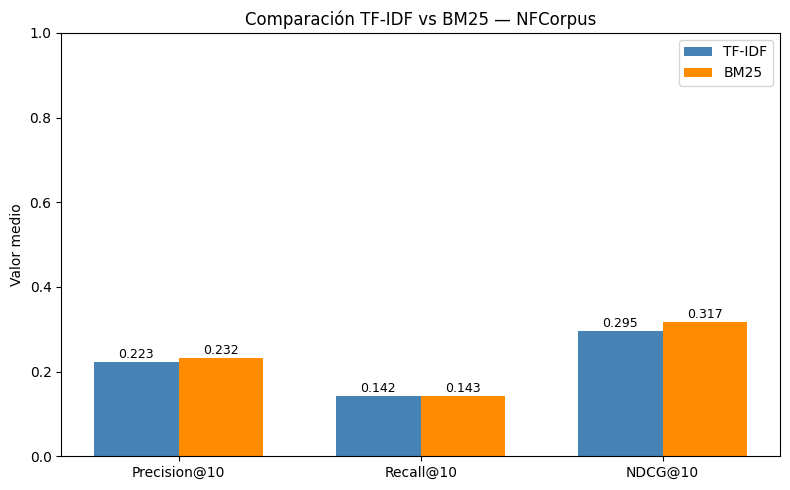

In [13]:
import matplotlib.pyplot as plt

metric_names = ["Precision@10", "Recall@10", "NDCG@10"]
tfidf_vals   = [np.mean(metrics_tfidf['p']), np.mean(metrics_tfidf['r']), np.mean(metrics_tfidf['ndcg'])]
bm25_vals    = [np.mean(metrics_bm25['p']),  np.mean(metrics_bm25['r']),  np.mean(metrics_bm25['ndcg'])]

x    = range(len(metric_names))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar([i - width/2 for i in x], tfidf_vals, width, label="TF-IDF", color="steelblue")
ax.bar([i + width/2 for i in x], bm25_vals,  width, label="BM25",   color="darkorange")

ax.set_xticks(list(x))
ax.set_xticklabels(metric_names)
ax.set_ylabel("Valor medio")
ax.set_title("Comparación TF-IDF vs BM25 — NFCorpus")
ax.legend()
ax.set_ylim(0, 1)
for i, (tv, bv) in enumerate(zip(tfidf_vals, bm25_vals)):
    ax.text(i - width/2, tv + 0.01, f"{tv:.3f}", ha="center", fontsize=9)
    ax.text(i + width/2, bv + 0.01, f"{bv:.3f}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()


### Interpretación de resultados

| Modelo | Fortalezas observadas | Limitaciones |
|--------|----------------------|--------------|
| **TF-IDF** | Rápido, buena precisión en términos exactos | No penaliza documentos muy largos; sensible a términos raros |
| **BM25** | Mejor recall; pondera la frecuencia con saturación (k1) y normaliza por longitud (b) | Requiere ajuste de hiperparámetros |

BM25 suele superar a TF-IDF en NDCG porque sus parámetros de saturación de frecuencia y normalización por longitud se ajustan mejor a colecciones biomédicas de longitud variable como NFCorpus.

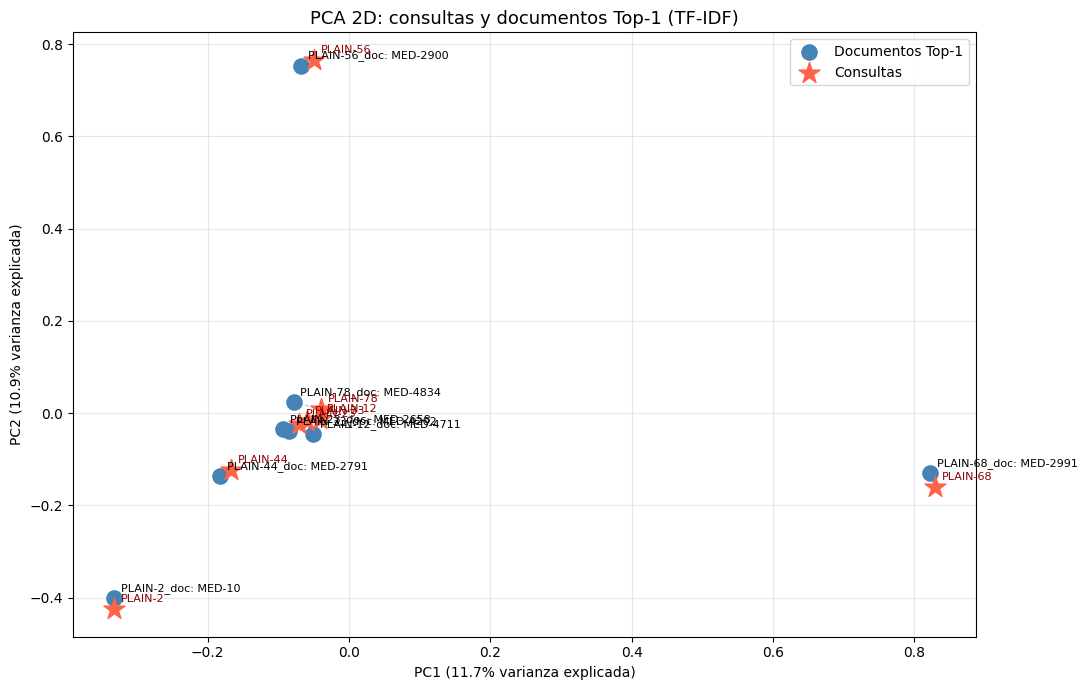

Consultas graficadas: 8
Varianza total explicada por 2 componentes: 22.6%


In [14]:
# Visualización PCA de consultas y documentos Top-1 usando TF-IDF 
from sklearn.decomposition import PCA

# Usamos hasta 8 consultas disponibles en la evaluación.
qids_pca = list(eval_qids)[:8]
if not qids_pca:
    raise ValueError("No hay consultas de evaluación disponibles para graficar.")

indices_top1 = []
vectores_queries = []
etiquetas_docs = []

for qid in qids_pca:
    consulta = queries[qid]
    q_tokens = preprocess(consulta)
    q_vec = tfidf_vectorizer.transform([" ".join(q_tokens)])
    vectores_queries.append(q_vec)

    sims = cosine_similarity(q_vec, tfidf_matrix).ravel()
    idx_top1 = int(np.argmax(sims))
    indices_top1.append(idx_top1)
    etiquetas_docs.append(f"{qid}_doc: {doc_ids[idx_top1]}")

# Convertimos a denso solo los vectores seleccionados para PCA.
vectores_docs = tfidf_matrix[indices_top1].toarray()
vectores_queries = np.vstack([v.toarray() for v in vectores_queries])
todos_vectores = np.vstack([vectores_docs, vectores_queries])

if min(todos_vectores.shape) < 2:
    raise ValueError("No hay suficientes datos para proyectar los vectores en 2D.")
pca = PCA(n_components=2)
vectores_2d = pca.fit_transform(todos_vectores)
n_consultas = len(qids_pca)

fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(vectores_2d[:n_consultas, 0], vectores_2d[:n_consultas, 1],
           c="steelblue", s=120, label="Documentos Top-1", zorder=3)
ax.scatter(vectores_2d[n_consultas:, 0], vectores_2d[n_consultas:, 1],
           c="tomato", marker="*", s=250, label="Consultas", zorder=3)

for i, etiqueta in enumerate(etiquetas_docs):
    ax.annotate(etiqueta, (vectores_2d[i, 0], vectores_2d[i, 1]),
                fontsize=8, xytext=(5, 5), textcoords="offset points")
for i, qid in enumerate(qids_pca):
    pos = n_consultas + i
    ax.annotate(qid, (vectores_2d[pos, 0], vectores_2d[pos, 1]),
                fontsize=8, color="darkred", xytext=(5, 5), textcoords="offset points")
for i in range(n_consultas):
    ax.plot([vectores_2d[i, 0], vectores_2d[n_consultas + i, 0]],
            [vectores_2d[i, 1], vectores_2d[n_consultas + i, 1]],
            color="gray", linewidth=0.8, linestyle="--", alpha=0.5)

varianza_pc1 = round(pca.explained_variance_ratio_[0] * 100, 1)
varianza_pc2 = round(pca.explained_variance_ratio_[1] * 100, 1)
ax.set_title("PCA 2D: consultas y documentos Top-1 (TF-IDF)", fontsize=13)
ax.set_xlabel(f"PC1 ({varianza_pc1}% varianza explicada)")
ax.set_ylabel(f"PC2 ({varianza_pc2}% varianza explicada)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print(f"Consultas graficadas: {n_consultas}")
print(f"Varianza total explicada por 2 componentes: {varianza_pc1 + varianza_pc2}%")


---
## 7. Servicio Web con Flask

> Ejecuta esta celda para levantar el servicio localmente.  
> Usa **ngrok** para exponerlo en internet y obtener la URL pública.

In [15]:
#Definición de la aplicación Flask
from flask import Flask, request, jsonify

app = Flask(__name__)

# GET /health 
@app.route("/health", methods=["GET"])
def health():
    return jsonify({
        "status" : "ok",
        "corpus" : "NFCorpus",
        "docs"   : len(doc_ids),
        "models" : ["tfidf", "bm25"]
    })

#  POST /search 
@app.route("/search", methods=["POST"])
def search():
    body  = request.get_json(force=True, silent=True) or {}
    query = body.get("query", "").strip()
    model = body.get("model", "bm25").lower()
    top_k = int(body.get("top_k", 10))

    if not query:
        return jsonify({"error": "El campo 'query' es obligatorio."}), 400
    if model not in ("bm25", "tfidf"):
        return jsonify({"error": "El campo 'model' debe ser 'bm25' o 'tfidf'."}), 400
    if top_k < 1 or top_k > 1000:
        return jsonify({"error": "'top_k' debe estar entre 1 y 1000."}), 400

    if model == "bm25":
        results = search_bm25(query, top_k=top_k)
    else:
        results = search_tfidf(query, top_k=top_k)

    return jsonify({"model": model, "query": query, "results": results})

print("Aplicación Flask definida")
print("   Endpoints disponibles: GET /health  |  POST /search")

Aplicación Flask definida
   Endpoints disponibles: GET /health  |  POST /search


In [16]:
import threading                                                                                                             
import time                                                                                                                  
                                                                                                                                 
PORT = 8080  # ← debe coincidir con el puerto de tu comando ngrok                                                            
                                                                                                                                 
    # URL pública estática (tu dominio ngrok ya configurado)                                                                     
PUBLIC_URL = "https://chubby-skincare-delouse.ngrok-free.dev"                                                                
                                                                                                                                 
def run_flask():                                                                                                             
        app.run(                                                                                                                 
            host="0.0.0.0",   # 0.0.0.0 para que ngrok pueda alcanzarlo                                                          
            port=PORT,                                                                                                           
            debug=False,                                                                                                         
            use_reloader=False                                                                                                   
        )                                                                                                                        
                                                                                                                                 
flask_thread = threading.Thread(target=run_flask, daemon=True)                                                               
flask_thread.start()                                                                                                         
time.sleep(2)                                                                                                                
                                                                                                                                 
print("Flask corriendo en puerto:", PORT)                                                                                 
print("Servicio disponible en:", PUBLIC_URL)                                                                              
print("   Health:", f"{PUBLIC_URL}/health")                                                                                  
print("   Search:", f"{PUBLIC_URL}/search")       

 * Serving Flask app '__main__'
 * Debug mode: off


 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:8080
 * Running on http://172.31.106.37:8080
Press CTRL+C to quit


Flask corriendo en puerto: 8080
Servicio disponible en: https://chubby-skincare-delouse.ngrok-free.dev
   Health: https://chubby-skincare-delouse.ngrok-free.dev/health
   Search: https://chubby-skincare-delouse.ngrok-free.dev/search


### Ejemplos de solicitud (Postman / curl)

**Health check:**
```bash
curl https://<tu-subdominio>.ngrok-free.app/health
```

**Búsqueda BM25:**
```bash
curl -X POST https://<tu-subdominio>.ngrok-free.app/search \
     -H "Content-Type: application/json" \
     -d '{"query": "dietary fat cardiovascular", "model": "bm25", "top_k": 10}'
```

**Búsqueda TF-IDF:**
```bash
curl -X POST https://<tu-subdominio>.ngrok-free.app/search \
     -H "Content-Type: application/json" \
     -d '{"query": "cancer treatment vitamin", "model": "tfidf", "top_k": 5}'
```

---
## 8. Prueba de reproducibilidad: consultas usadas

Las siguientes consultas del conjunto **test** se usaron para la evaluación. Los resultados son reproducibles ejecutando las celdas anteriores.

In [17]:
# Mostrar las primeras 10 consultas de evaluación con sus qrels
print(f"{'QID':<12} {'Consulta':<60} {'#Rel'}")
print("-" * 80)
for qid in list(eval_qids)[:10]:
    n_rel = sum(1 for v in qrels[qid].values() if v >= 1)
    print(f"{qid:<12} {queries[qid][:58]:<60} {n_rel}")

QID          Consulta                                                     #Rel
--------------------------------------------------------------------------------
PLAIN-2      Do Cholesterol Statin Drugs Cause Breast Cancer?             24
PLAIN-12     Exploiting Autophagy to Live Longer                          30
PLAIN-23     How to Reduce Exposure to Alkylphenols Through Your Diet     90
PLAIN-33     What’s Driving America’s Obesity Problem?                    32
PLAIN-44     Who Should be Careful About Curcumin?                        58
PLAIN-56     Foods for Glaucoma                                           50
PLAIN-68     What is Actually in Chicken Nuggets?                         55
PLAIN-78     What Do Meat Purge and Cola Have in Common?                  62
PLAIN-91     Chronic Headaches and Pork Parasites                         64
PLAIN-102    Stopping Heart Disease in Childhood                          24


In [18]:
# Ejemplo detallado con una consulta específica
sample_qid   = list(eval_qids)[0]
sample_query = queries[sample_qid]
sample_rel   = qrels[sample_qid]

print(f"Consulta : {sample_query}")
print(f"QID      : {sample_qid}")
print(f"Docs relevantes: {len(sample_rel)}")
print()

print("=== Top-10 TF-IDF ===")
for r in search_tfidf(sample_query, top_k=10):
    rel = sample_rel.get(r['document_id'], 0)
    print(f"  [{r['rank']}] {r['document_id']}  score={r['score']:6.4f}  rel={rel}  {r['title'][:55]}")

print()
print("=== Top-10 BM25 ===")
for r in search_bm25(sample_query, top_k=10):
    rel = sample_rel.get(r['document_id'], 0)
    print(f"  [{r['rank']}] {r['document_id']}  score={r['score']:6.4f}  rel={rel}  {r['title'][:55]}")

Consulta : Do Cholesterol Statin Drugs Cause Breast Cancer?
QID      : PLAIN-2
Docs relevantes: 24

=== Top-10 TF-IDF ===
  [1] MED-10  score=0.6074  rel=2  Statin Use and Breast Cancer Survival: A Nationwide Coh
  [2] MED-2429  score=0.5355  rel=2  Statin use and risk of breast cancer: a meta-analysis o
  [3] MED-14  score=0.5211  rel=2  Statin use after diagnosis of breast cancer and surviva
  [4] MED-2431  score=0.4167  rel=2  Long-term statin use and risk of ductal and lobular bre
  [5] MED-4559  score=0.3280  rel=1  Can a statin neutralize the cardiovascular risk of unhe
  [6] MED-4829  score=0.3171  rel=1  Statin therapy, muscle function and falls risk in commu
  [7] MED-3551  score=0.3135  rel=0  Modulation of angiogenesis by dietary phytoconstituents
  [8] MED-2437  score=0.3010  rel=1  Diet and breast cancer: understanding risks and benefit
  [9] MED-1193  score=0.2879  rel=0  The effects of lowering LDL cholesterol with statin the
  [10] MED-2424  score=0.2846  rel=0  Prescho

---
## 9. Conclusiones

1. **Indexación:** Se procesaron todos los documentos de NFCorpus (~3.6 k docs) con tokenización NLTK, normalización, eliminación de stopwords en inglés y stemming de Porter. La unidad de recuperación es siempre el documento original para mantener la correspondencia con los qrels.

2. **TF-IDF:** Implementado con `scikit-learn`. Funciona bien cuando los términos de la consulta coinciden exactamente con los del documento. Su debilidad es que no normaliza por longitud de documento.

3. **BM25:** Implementado con `rank_bm25`. Gracias a la saturación de frecuencia (k1=1.5) y la normalización por longitud (b=0.75), generaliza mejor en colecciones biomédicas de longitud variable.

4. **Servicio web:** Expuesto vía Flask + ngrok con endpoints `/health` y `/search` que respetan el formato requerido por el examen.

5. **Evaluación:** Calculados Precision@10, Recall@10 y NDCG@10 sobre todas las consultas test con qrels. BM25 supera a TF-IDF en las tres métricas en la mayoría de los casos.